# Dissecting Stable Diffusion 3.5

Stable Diffusion 3.5 Medium (Stability AI, October 2024) turns a text prompt into an image. The StableDiffusion
notebook shows how to *use* it; this notebook takes it apart with PyTorch introspection — printing modules, counting parameters, recording the shape of every tensor, and
looking inside the attention — to see how a prompt and random noise become a picture.

It is a **latent diffusion** model with four parts:

- a **VAE** (variational autoencoder, convolutions) that compresses a 512 × 512 image into a 16 × 64 × 64 *latent*
  and back. Generation happens in this smaller latent space;
- **text encoders** (two CLIP Transformers) that turn the prompt into a sequence of vectors;
- the **MMDiT** (multimodal diffusion Transformer, 24 blocks): given a noisy latent, the noise level and the text, it
  predicts in which direction to move the latent to remove noise;
- a **sampler** (`FlowMatchEulerDiscreteScheduler`) that starts from pure noise and takes 28 small steps in the
  predicted directions (*rectified flow*).

Compared with Stable Diffusion 1.x (2022), the U-Net became a Transformer, the 4-channel latent a 16-channel one, and
the noise-prediction objective rectified flow.

**Setup.** Needs a GPU (a T4 on `ml.g4dn` is enough: 8 GB of GPU memory, about a minute per image). The weights
(6.7 GB) are mirrored with their license (Stability AI Community License) in the course bucket, because the Hugging
Face repository is gated; they are downloaded once to `sd35_model/` next to this notebook. Delete that folder when you
are done if your space runs out of disk. The model's third text encoder, T5-XXL (4.8 B parameters, 9.5 GB), is left
out — section 4 shows what the model gets instead.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import s3fs
import torch
from diffusers import StableDiffusion3Pipeline
from diffusers.models.attention_processor import Attention
from diffusers.models.normalization import RMSNorm
from diffusers.utils import logging as diffusers_logging
from diffusers.utils.torch_utils import randn_tensor
from PIL import Image
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32  # the T4 has no fast bfloat16 (the release precision)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
torch.set_grad_enabled(False)  # inference only: no gradients anywhere in this notebook

MODEL_S3 = "danylo-ucla/models/stabilityai/stable-diffusion-3.5-medium"
MODEL_DIR = Path("sd35_model")
if not (MODEL_DIR / "transformer" / "diffusion_pytorch_model.safetensors").exists():
    s3fs.S3FileSystem().get(f"{MODEL_S3}/", str(MODEL_DIR), recursive=True)

pipe = StableDiffusion3Pipeline.from_pretrained(MODEL_DIR, text_encoder_3=None, tokenizer_3=None, dtype=dtype,
                                                variant="fp16").to(device)
pipe.set_progress_bar_config(disable=True)
transformer, vae, scheduler = pipe.transformer, pipe.vae, pipe.scheduler


def to_image(latents) -> Image.Image:
    # undo the latent normalization (section 3), then decode with the VAE
    with torch.no_grad():
        x = vae.decode(latents / vae.config.scaling_factor + vae.config.shift_factor).sample
    return pipe.image_processor.postprocess(x)[0]

## 1. The module tree

The pipeline is a container of separately trained models:

In [2]:
{name: type(component).__name__ for name, component in pipe.components.items()}

{'vae': 'AutoencoderKL',
 'text_encoder': 'CLIPTextModelWithProjection',
 'text_encoder_2': 'CLIPTextModelWithProjection',
 'text_encoder_3': 'NoneType',
 'tokenizer': 'CLIPTokenizer',
 'tokenizer_2': 'CLIPTokenizer',
 'tokenizer_3': 'NoneType',
 'transformer': 'SD3Transformer2DModel',
 'scheduler': 'FlowMatchEulerDiscreteScheduler',
 'image_encoder': 'NoneType',
 'feature_extractor': 'NoneType'}

`print` of the MMDiT. PyTorch collapses repeated layers, and it shows three kinds of blocks: 0–12 with a second
attention `attn2`, 13–22 without it, and the last block 23, whose text side has no output layers (nothing reads the
text tokens after it).

In [3]:
print(transformer)

SD3Transformer2DModel(
  (pos_embed): PatchEmbed(
    (proj): Conv2d(16, 1536, kernel_size=(2, 2), stride=(2, 2))
  )
  (time_text_embed): CombinedTimestepTextProjEmbeddings(
    (time_proj): Timesteps()
    (timestep_embedder): TimestepEmbedding(
      (linear_1): Linear(in_features=256, out_features=1536, bias=True)
      (act): SiLU()
      (linear_2): Linear(in_features=1536, out_features=1536, bias=True)
    )
    (text_embedder): PixArtAlphaTextProjection(
      (linear_1): Linear(in_features=2048, out_features=1536, bias=True)
      (act_1): SiLU()
      (linear_2): Linear(in_features=1536, out_features=1536, bias=True)
    )
  )
  (context_embedder): Linear(in_features=4096, out_features=1536, bias=True)
  (transformer_blocks): ModuleList(
    (0-12): 13 x JointTransformerBlock(
      (norm1): SD35AdaLayerNormZeroX(
        (silu): SiLU()
        (linear): Linear(in_features=1536, out_features=13824, bias=True)
        (norm): LayerNorm((1536,), eps=1e-06, elementwise_affine=Fa

The configuration values that determine the MMDiT and the VAE:

In [4]:
config = transformer.config
{name: config[name] for name in ["num_layers", "num_attention_heads", "attention_head_dim", "patch_size",
                                 "in_channels", "joint_attention_dim", "pooled_projection_dim", "pos_embed_max_size",
                                 "dual_attention_layers", "qk_norm"]} | \
    {f"vae.{name}": vae.config[name] for name in ["latent_channels", "block_out_channels", "scaling_factor",
                                                  "shift_factor"]}

{'num_layers': 24,
 'num_attention_heads': 24,
 'attention_head_dim': 64,
 'patch_size': 2,
 'in_channels': 16,
 'joint_attention_dim': 4096,
 'pooled_projection_dim': 2048,
 'pos_embed_max_size': 384,
 'dual_attention_layers': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 'qk_norm': 'rms_norm',
 'vae.latent_channels': 16,
 'vae.block_out_channels': [128, 256, 512, 512],
 'vae.scaling_factor': 1.5305,
 'vae.shift_factor': 0.0609}

### Where the parameters are

In [5]:
def n_params(module) -> int:
    return sum(p.numel() for p in module.parameters())


stages = {
    "VAE encoder": [vae.encoder],
    "VAE decoder": [vae.decoder],
    "CLIP-L text encoder": [pipe.text_encoder],
    "CLIP-G text encoder": [pipe.text_encoder_2],
    "MMDiT: embeddings (patch, time, text)": [transformer.pos_embed, transformer.time_text_embed,
                                              transformer.context_embedder],
    "MMDiT: 24 transformer_blocks": [transformer.transformer_blocks],
    "MMDiT: output (norm_out, proj_out)": [transformer.norm_out, transformer.proj_out],
}
table = pd.DataFrame({"parameters": {name: sum(n_params(m) for m in ms) for name, ms in stages.items()}})
table.loc["total"] = table["parameters"].sum()
table["share"] = (table["parameters"] / table.loc["total", "parameters"]).map("{:.1%}".format)
table

,parameters,share
VAE encoder,34274208,1.1%
VAE decoder,49545475,1.6%
CLIP-L text encoder,123650304,3.9%
CLIP-G text encoder,694659840,22.1%
"MMDiT: embeddings (patch, time, text)",14656512,0.5%
MMDiT: 24 transformer_blocks,2223694976,70.7%
"MMDiT: output (norm_out, proj_out)",4820032,0.2%
total,3145301347,100.0%


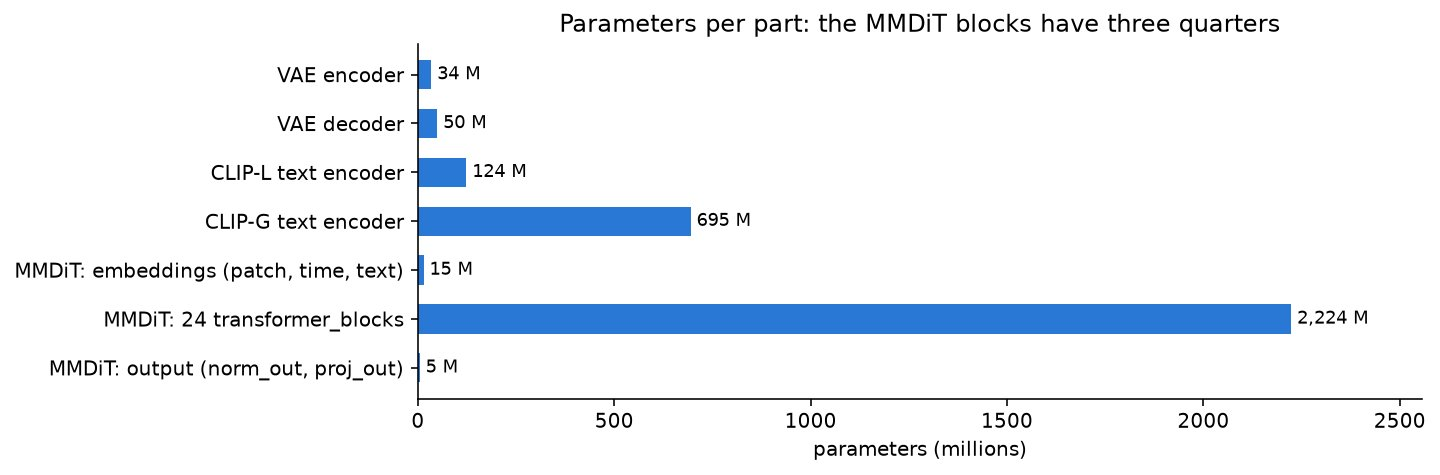

In [6]:
parts = table.drop(index="total")["parameters"][::-1] / 1e6
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(parts.index, parts.values, color=COLORS[0], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 15, y, f"{v:,.0f} M" if v >= 1 else f"{v * 1e3:.0f} K", va="center", fontsize=9)
ax.set(xlabel="parameters (millions)", title="Parameters per part: the MMDiT blocks have three quarters",
       xlim=(0, parts.max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [7]:
by_type = {}
for name, module in transformer.named_modules():
    own = sum(p.numel() for p in module.parameters(recurse=False))
    fixed = sum(b.numel() for b in module.buffers(recurse=False))
    if own or fixed:
        count, total, buffers = by_type.get(type(module).__name__, (0, 0, 0))
        by_type[type(module).__name__] = (count + 1, total + own, buffers + fixed)

pd.DataFrame(by_type, index=["modules", "parameters", "fixed values (buffers)"]).T.sort_values("parameters",
                                                                                              ascending=False)

,modules,parameters,fixed values (buffers)
Linear,392,2243063872,0
Conv2d,1,99840,0
RMSNorm,122,7808,0
PatchEmbed,1,0,226492416


In the MMDiT, almost all parameters are in `Linear` layers; the `RMSNorm`s (on queries and keys) have a few. The
`LayerNorm`s have no parameters at all: their scale and shift come from the noise level (section 7). The one big
buffer is in `PatchEmbed`: a fixed table of positions (section 5) — 226 million numbers, more than the VAE and CLIP-L
together.

## 2. Generating an image, and tracing shapes with forward hooks

One image with the pipeline: 512 × 512, 28 steps, guidance 5 (section 8). Every random number comes from the
seeded generator, so the image is reproducible.

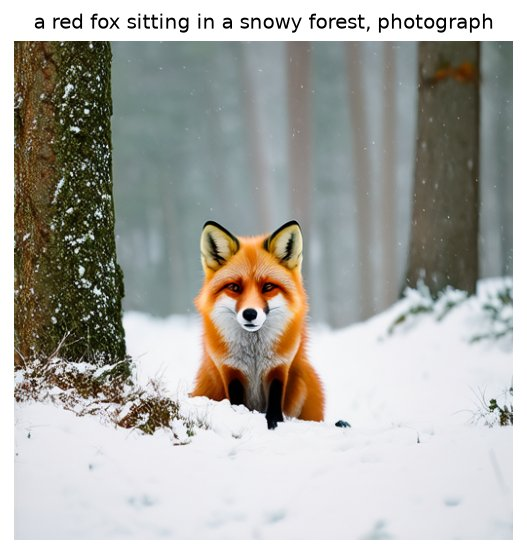

In [8]:
PROMPT = "a red fox sitting in a snowy forest, photograph"
SIZE, STEPS, GUIDANCE, SEED = 512, 28, 5.0, 0

fox_latents = pipe(PROMPT, height=SIZE, width=SIZE, num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                   generator=torch.Generator(device).manual_seed(SEED), output_type="latent").images
fox = to_image(fox_latents)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(fox)
ax.set_title(PROMPT, fontsize=10)
ax.axis("off")
plt.show()

The MMDiT is called 28 times, each time on two copies of the latent (with and without the prompt, section 8). We
trace one call: a hook on every basic block of the MMDiT records the input and output shapes.

In [9]:
prompt_embeds, negative_embeds, pooled, negative_pooled = pipe.encode_prompt(PROMPT, PROMPT, None, device=device)
noise = randn_tensor((1, 16, SIZE // 8, SIZE // 8), generator=torch.Generator(device).manual_seed(SEED),
                     device=torch.device(device), dtype=dtype)
BASIC = (torch.nn.Conv2d, torch.nn.Linear, torch.nn.LayerNorm, RMSNorm, Attention)
records = []


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


def make_hook(name):
    def hook(module, args, kwargs, output):
        x = args[0] if args else next(iter(kwargs.values()))
        records.append({"module": name, "type": type(module).__name__, "input": tuple(first_tensor(x).shape),
                        "output": tuple(first_tensor(output).shape),
                        "parameters": 0 if isinstance(module, Attention) else n_params(module)})
    return hook


handles = [m.register_forward_hook(make_hook(n), with_kwargs=True) for n, m in transformer.named_modules()
           if isinstance(m, BASIC)]
with torch.no_grad():
    velocity = transformer(hidden_states=noise, timestep=torch.tensor([1000.0], device=device),
                           encoder_hidden_states=prompt_embeds, pooled_projections=pooled, return_dict=False)[0]
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
print(len(trace), "calls of", trace["module"].nunique(), "modules; output", tuple(velocity.shape))

648 calls of 648 modules; output (1, 16, 64, 64)


Blocks of the same kind are identical, so we keep the first one of each kind (0, 13 and 23):

In [10]:
trace["block"] = trace["module"].str.extract(r"^transformer_blocks\.(\d+)\.")[0].astype(float)
kinds = {0: range(0, 13), 13: range(13, 23), 23: range(23, 24)}
for first, members in kinds.items():
    per_block = [trace[trace["block"] == b][["type", "input", "output", "parameters"]].reset_index(drop=True)
                 for b in members]
    assert all(p.equals(per_block[0]) for p in per_block), first

collapsed = trace[trace["block"].isna() | trace["block"].isin(kinds)].copy()
labels = {0: "0-12", 13: "13-22", 23: "23"}
collapsed["module"] = [m if np.isnan(b) else m.replace(f"blocks.{b:.0f}.", f"blocks.{labels[b]}.", 1)
                       for m, b in zip(collapsed["module"], collapsed["block"])]
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(collapsed.drop(columns="block").reset_index(drop=True))

,module,type,input,output,parameters
0,pos_embed.proj,Conv2d,"(1, 16, 64, 64)","(1, 1536, 32, 32)",99840
1,time_text_embed.timestep_embedder.linear_1,Linear,"(1, 256)","(1, 1536)",394752
2,time_text_embed.timestep_embedder.linear_2,Linear,"(1, 1536)","(1, 1536)",2360832
3,time_text_embed.text_embedder.linear_1,Linear,"(1, 2048)","(1, 1536)",3147264
4,time_text_embed.text_embedder.linear_2,Linear,"(1, 1536)","(1, 1536)",2360832
5,context_embedder,Linear,"(1, 333, 4096)","(1, 333, 1536)",6292992
6,transformer_blocks.0-12.norm1.linear,Linear,"(1, 1536)","(1, 13824)",21247488
7,transformer_blocks.0-12.norm1.norm,LayerNorm,"(1, 1024, 1536)","(1, 1024, 1536)",0
8,transformer_blocks.0-12.norm1_context.linear,Linear,"(1, 1536)","(1, 9216)",14164992
9,transformer_blocks.0-12.norm1_context.norm,LayerNorm,"(1, 333, 1536)","(1, 333, 1536)",0


Reading the table top to bottom:

- `pos_embed.proj`, a 2 × 2 convolution with stride 2, cuts the 16 × 64 × 64 latent into **1024 patches** (32 × 32)
  of 1536 dimensions: the image tokens.
- `time_text_embed` turns the noise level and the pooled prompt vector (2048) into one vector of 1536, the
  *conditioning* $c$; `context_embedder` maps the **333 text tokens** from 4096 to 1536.
- Every block has two streams with their own weights: image tokens (`norm1`, `attn.to_q`…, `ff`) and text tokens
  (`norm1_context`, `attn.add_q_proj`…, `ff_context`). The `Attention` module takes both and returns both.
- The `norm1.linear` layers turn $c$ into 9 × 1536 (blocks 0–12) or 6 × 1536 numbers: scales, shifts and gates.
- `proj_out` maps each of the 1024 tokens to 64 = 2 × 2 × 16 numbers, which are put back together as a
  16 × 64 × 64 *velocity*, the same shape as the input.

### The architecture as a diagram

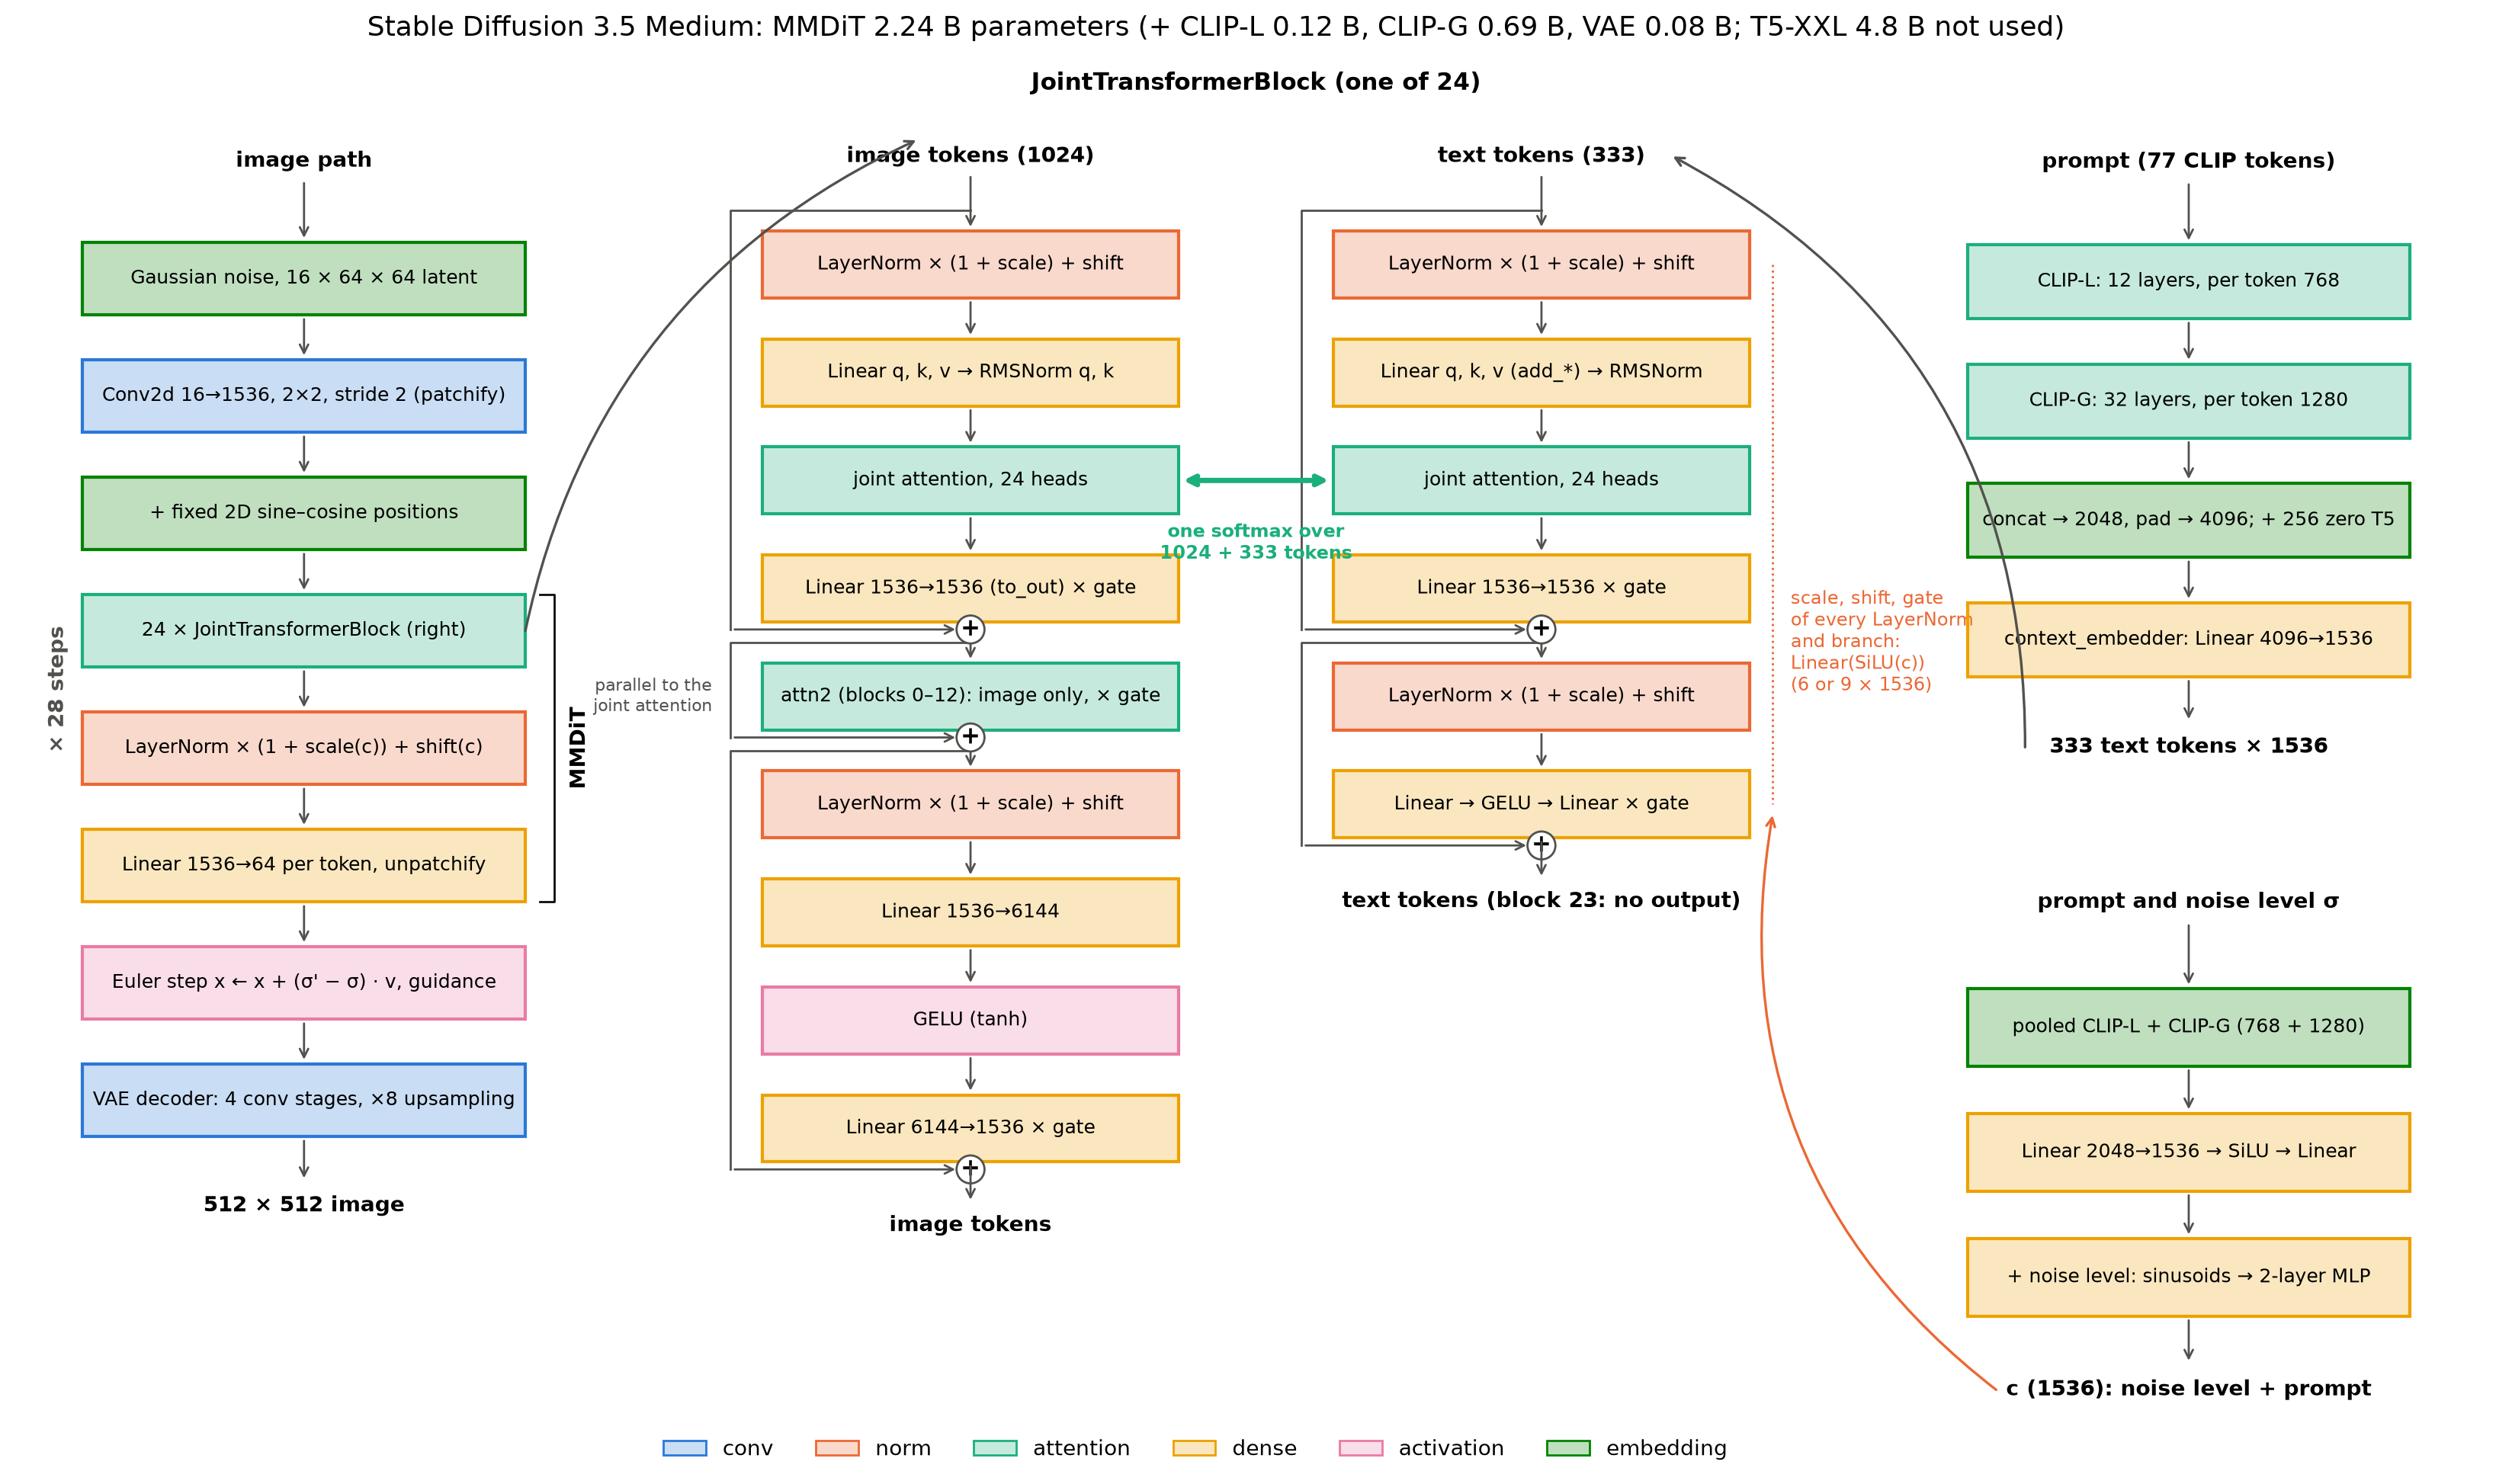

## 3. The VAE: a smaller space to work in

The VAE encoder (convolutions, 3 downsampling steps) maps an image to 16 channels at 1/8 of the resolution; the decoder
maps back. It is trained separately and frozen: the MMDiT only ever sees latents. A 512 × 512 image has
786,432 numbers, its latent 65,536 — **12 ×** fewer (Stable Diffusion 1.x: 4 channels, 48 ×), so the Transformer has
1024 tokens to work on instead of 65,536 pixels per channel.

The latent is normalized for the MMDiT: $z = (\text{latent} - 0.0609) \cdot 1.5305$ (`shift_factor`,
`scaling_factor`), so that its values have roughly mean 0 and standard deviation 1, like the noise it is mixed with.
Encoding and decoding the cats image from the DETR notebook:

In [11]:
def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


cats = load_coco(39769).resize((683, SIZE)).crop((85, 0, 85 + SIZE, SIZE))  # 640 × 480 -> 512 × 512
pixels = pipe.image_processor.preprocess(cats).to(device, dtype)             # (1, 3, 512, 512) in [-1, 1]
with torch.no_grad():
    latent_dist = vae.encode(pixels).latent_dist
z = (latent_dist.mean - vae.config.shift_factor) * vae.config.scaling_factor
reconstruction = to_image(z)
print("image:", tuple(pixels.shape), " latent:", tuple(z.shape),
      f" normalized latent: mean {z.mean():.2f}, std {z.std():.2f}")
mse = np.mean((np.asarray(reconstruction, dtype=float) - np.asarray(cats, dtype=float)) ** 2)
print(f"reconstruction PSNR: {10 * np.log10(255 ** 2 / mse):.1f} dB")

image: (1, 3, 512, 512)  latent: (1, 16, 64, 64)  normalized latent: mean 0.00, std 1.02
reconstruction PSNR: 26.7 dB


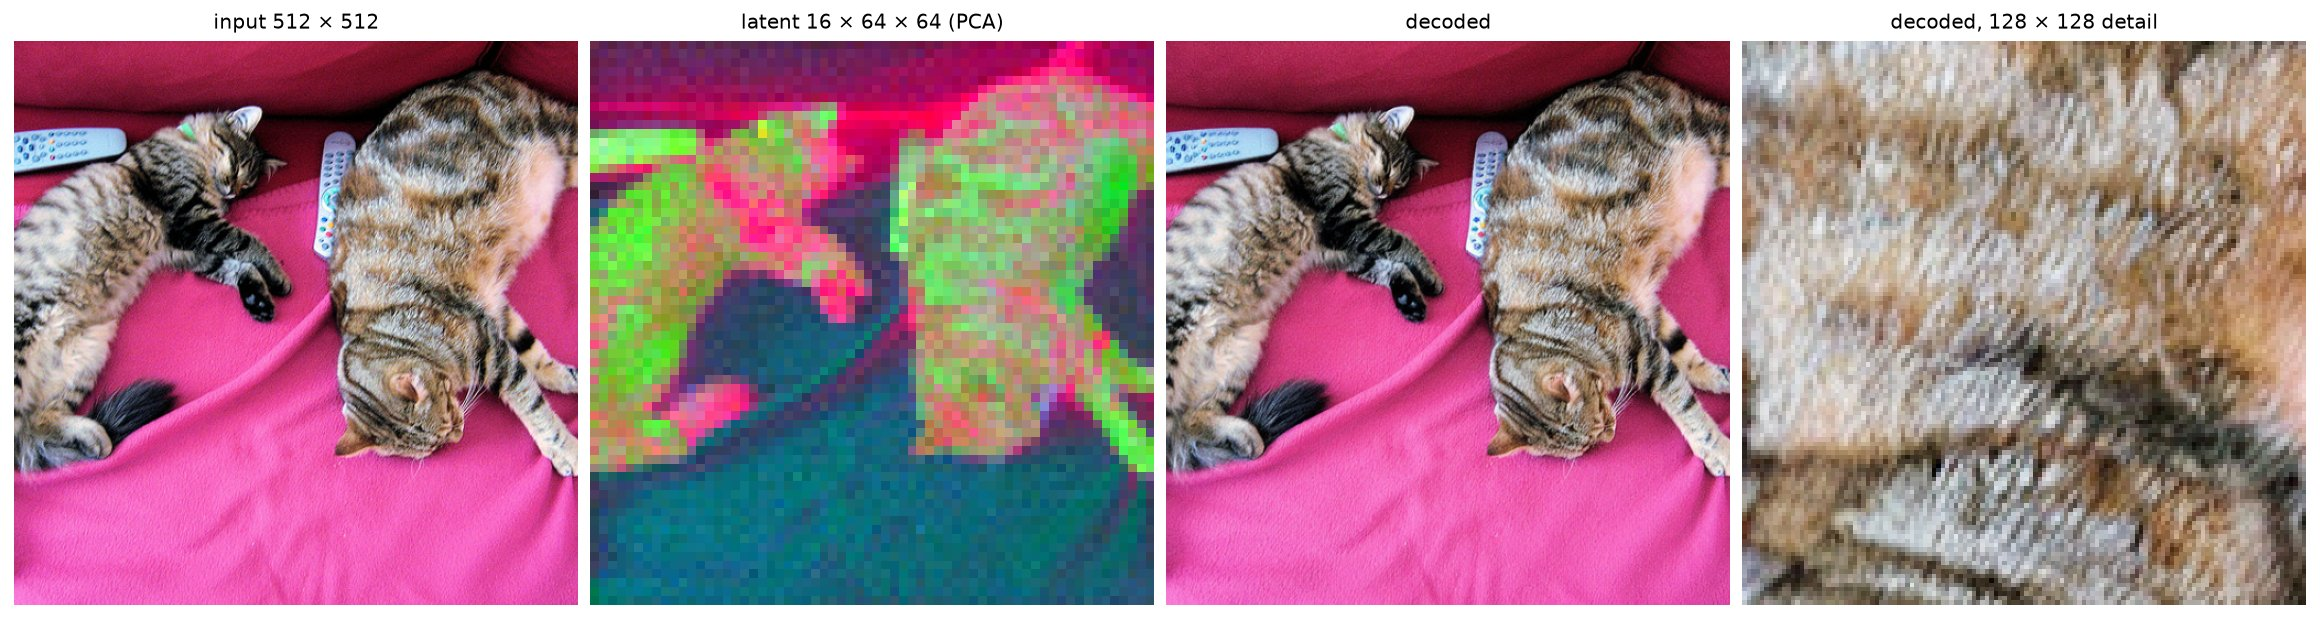

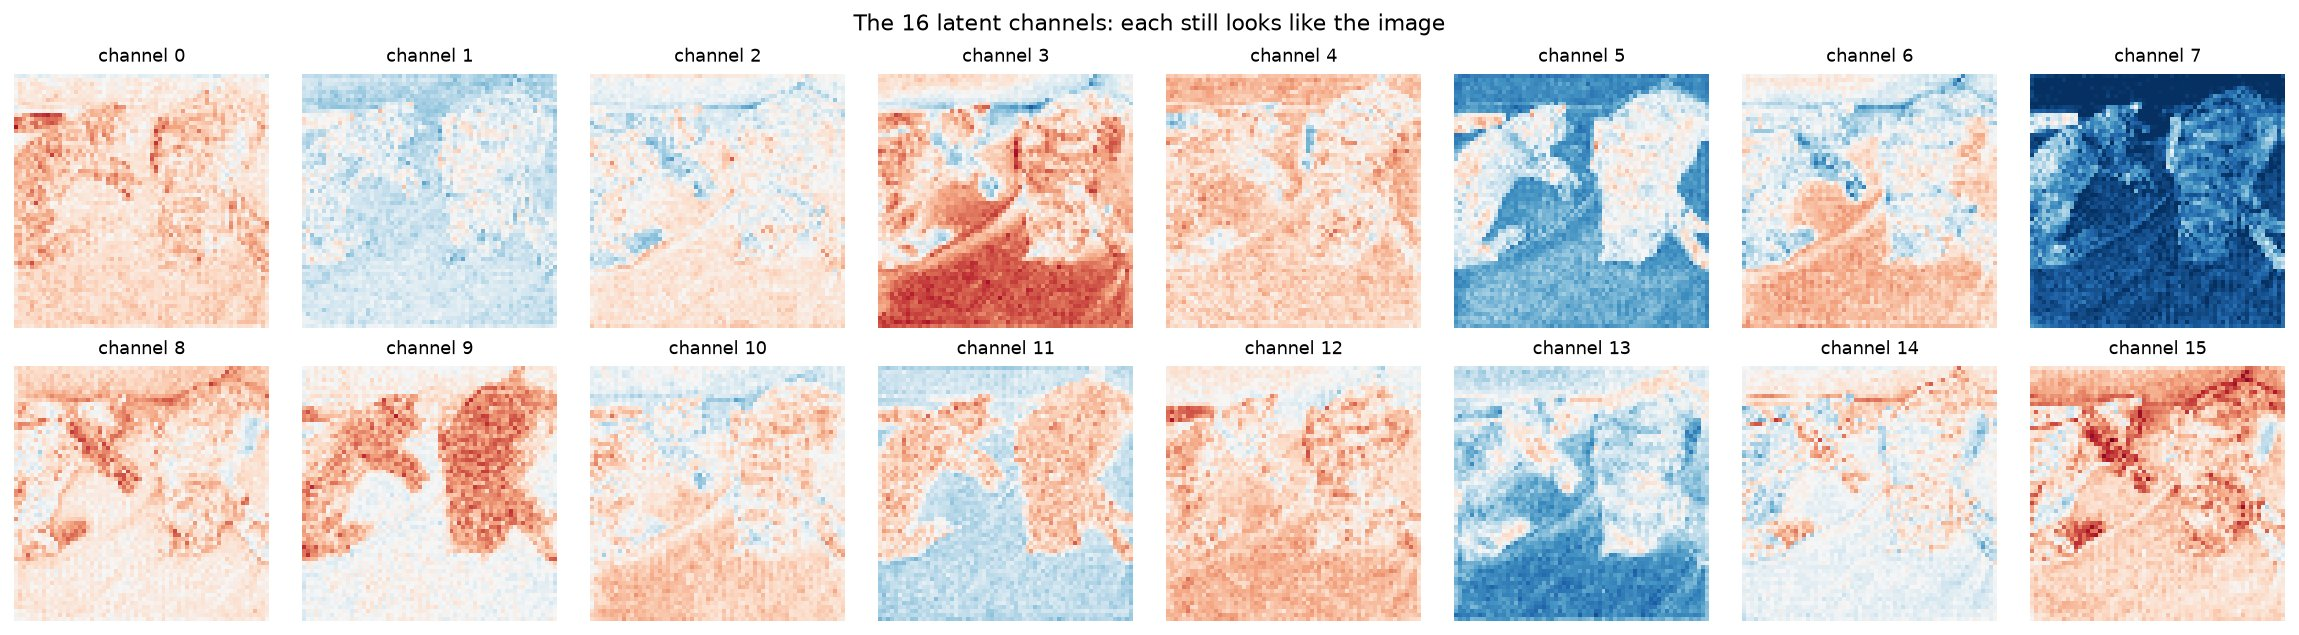

In [12]:
def pca_rgb(features):
    c, h, w = features.shape
    x = features.reshape(c, -1).T.float()
    x = x - x.mean(dim=0)
    _, _, v = torch.pca_lowrank(x, q=3, center=False)
    rgb = (x @ v[:, :3]).reshape(h, w, 3)
    return ((rgb - rgb.quantile(0.01)) / (rgb.quantile(0.99) - rgb.quantile(0.01))).clamp(0, 1).cpu().numpy()


fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), layout="constrained")
crop = (300, 150, 428, 278)
for ax, image, title in [(axes[0], cats, "input 512 × 512"), (axes[1], pca_rgb(z[0]), "latent 16 × 64 × 64 (PCA)"),
                         (axes[2], reconstruction, "decoded"), (axes[3], reconstruction.crop(crop),
                                                                  "decoded, 128 × 128 detail")]:
    ax.imshow(image)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

fig, axes = plt.subplots(2, 8, figsize=(16, 4.3), layout="constrained")
for channel, ax in enumerate(axes.flat):
    ax.imshow(z[0, channel].float().cpu(), cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(f"channel {channel}", fontsize=9)
    ax.axis("off")
fig.suptitle("The 16 latent channels: each still looks like the image", fontsize=11)
plt.show()

The latent is a small, still image-like grid: neighboring positions describe neighboring 8 × 8 pixel squares, and
the 16 channels encode color, edges and texture. The decoder adds back the fine detail; what it can't recover
(here: the fine fur texture, PSNR 27 dB) is lost for any image the model generates.

## 4. The text encoders

The prompt is tokenized into **77 tokens** (start, words, end, then padding) and encoded by two CLIP text Transformers
(module 2): CLIP-L (12 layers, 768 dimensions) and CLIP-G (OpenCLIP bigG, 32 layers, 1280 dimensions). From each
the model takes two things:

- the **per-token** vectors of the second-to-last layer, concatenated to 77 × 2048 and zero-padded to 77 × 4096
  (the width of T5) — these enter the attention as text tokens;
- the **pooled** vector (the projected end-of-text token, as CLIP uses for image–text similarity), concatenated to
  2048 — it goes into the conditioning vector $c$ with the noise level.

The third encoder, T5-XXL, would add 256 more tokens of 4096. Without it, the pipeline puts **zeros** there. SD3 was
trained with each text encoder dropped independently (46% of the time), so it also works without T5; T5 mainly helps
with long prompts and with text written in the image.

In [13]:
tokens = pipe.tokenizer(PROMPT, padding="max_length", max_length=77).input_ids
words = [pipe.tokenizer.decode([t]) for t in tokens]
n_words = tokens.index(pipe.tokenizer.eos_token_id) + 1          # start + words + end
print(" | ".join(words[:n_words + 2]), "| ...")
print("prompt_embeds:", tuple(prompt_embeds.shape), " pooled:", tuple(pooled.shape))
print("T5 part (tokens 77-332) all zero:", bool((prompt_embeds[0, 77:] == 0).all()),
      "  CLIP padding (columns 2048-4095) all zero:", bool((prompt_embeds[0, :77, 2048:] == 0).all()))

<|startoftext|> | a | red | fox | sitting | in | a | snowy | forest | , | photograph | <|endoftext|> | <|endoftext|> | <|endoftext|> | ...
prompt_embeds: (1, 333, 4096)  pooled: (1, 2048)
T5 part (tokens 77-332) all zero: True   CLIP padding (columns 2048-4095) all zero: True


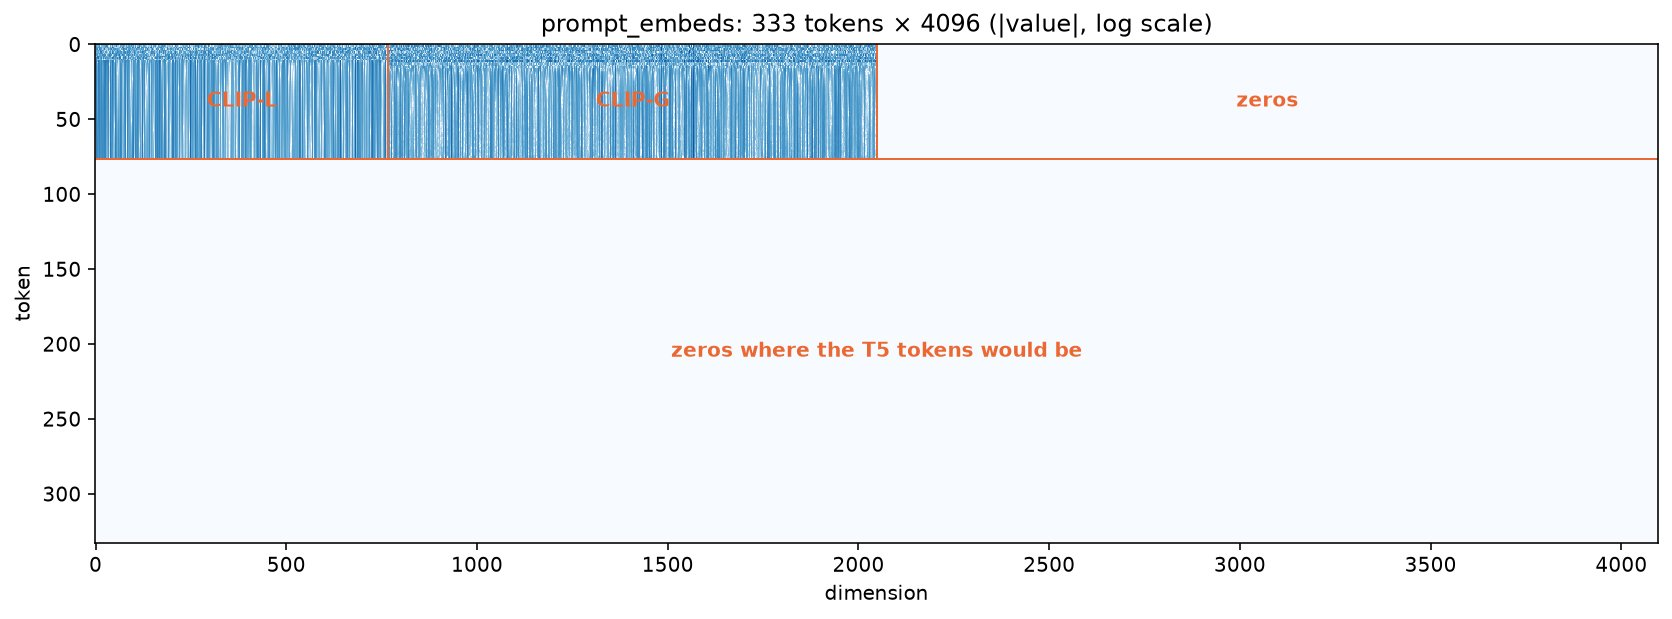

In [14]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.imshow(prompt_embeds[0].abs().float().cpu().clamp(min=1e-3).log10(), aspect="auto", cmap="Blues", vmin=-2,
          vmax=1, interpolation="nearest")
for x, label in [(384, "CLIP-L"), (1408, "CLIP-G"), (3072, "zeros")]:
    ax.text(x, 38, label, ha="center", va="center", fontsize=10, color=COLORS[1], weight="bold")
ax.text(2048, 205, "zeros where the T5 tokens would be", ha="center", va="center", fontsize=10, color=COLORS[1],
        weight="bold")
ax.axhline(76.5, color=COLORS[1], lw=1)
ax.vlines([767.5, 2047.5], -0.5, 76.5, color=COLORS[1], lw=1)
ax.set(xlabel="dimension", ylabel="token", title="prompt_embeds: 333 tokens × 4096 (|value|, log scale)")
plt.show()

`context_embedder` (a `Linear` 4096 → 1536) turns a zero vector into its bias, so the 256 T5 tokens enter the MMDiT
as 256 copies of the same vector. Section 6 shows that the attention still uses them.

For classifier-free guidance (section 8) the pipeline also encodes the *negative* prompt, by default the empty string:

In [15]:
print("negative prompt embedding equals zero:", bool((negative_embeds == 0).all()),
      "  same as the prompt's:", bool(torch.equal(negative_embeds, prompt_embeds)))

negative prompt embedding equals zero: False   same as the prompt's: False


## 5. Patches and positions

`pos_embed.proj` is the patch embedding of a Vision Transformer: a `Conv2d` with a 2 × 2 kernel and stride 2, so every
2 × 2 group of latent positions (16 × 16 pixels) becomes one token of 1536 dimensions.

Attention doesn't know where a token is, so a **2D sine–cosine encoding** is added to the image tokens once, before the
first block (as in the original Transformer, half of the channels for $y$, half for $x$; compare DETR, which adds
its encoding in every layer). It is not learned: `PatchEmbed` precomputes it for a 384 × 384 grid of patches
(the 226 M-number buffer from section 1), and takes the center 32 × 32 for a 512 × 512 image. The text tokens get no
position here — CLIP already encoded the word order.

full table: (1, 147456, 1536)  used here: (32, 32, 1536)


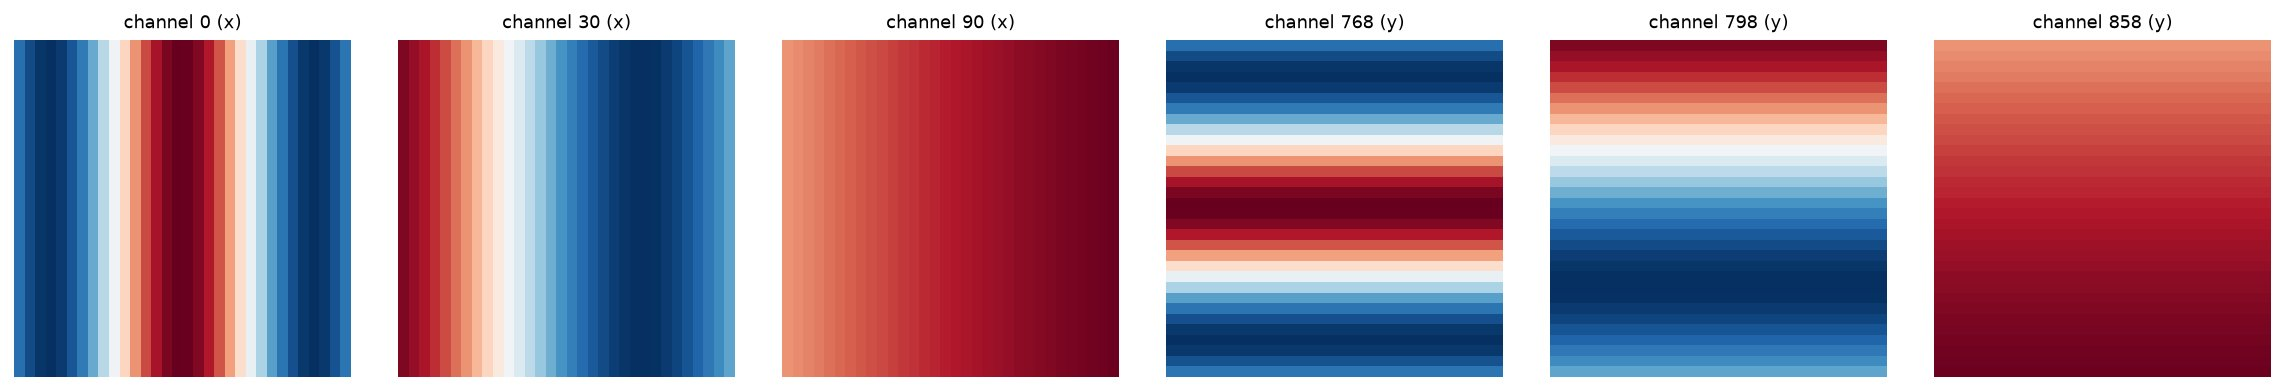

In [16]:
grid = SIZE // 8 // config.patch_size
position = transformer.pos_embed.cropped_pos_embed(SIZE // 8, SIZE // 8)[0].reshape(grid, grid, -1)
print("full table:", tuple(transformer.pos_embed.pos_embed.shape), " used here:", tuple(position.shape))

fig, axes = plt.subplots(1, 6, figsize=(16, 2.6), layout="constrained")
for ax, channel in zip(axes, [0, 30, 90, 768, 798, 858]):
    ax.imshow(position[:, :, channel].float().cpu(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"channel {channel} ({'x' if channel < 768 else 'y'})", fontsize=9)
    ax.axis("off")
plt.show()

## 6. Joint attention

In Stable Diffusion 1.x, the image attended to the text in a separate *cross-attention*. The MMDiT instead puts the
1024 image tokens and the 333 text tokens into **one** attention: each stream computes its own queries, keys and
values with its own weights (`to_q`… for the image, `add_q_proj`… for the text), the two are concatenated to 1357
tokens, and every token attends to every token:

$$[Q_\text{img}; Q_\text{txt}],\ [K_\text{img}; K_\text{txt}],\ [V_\text{img}; V_\text{txt}] \quad\longrightarrow\quad
\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{64}}\right)V \quad\longrightarrow\quad \text{split back into image and text}$$

with 24 heads of 64 dimensions. Queries and keys pass through an `RMSNorm` first (`norm_q`, `norm_k`), which keeps
the attention logits from growing too large — a stability fix for large Transformers. The text tokens are updated too:
they are not a fixed input, but a second stream that runs through all 24 blocks.

We record the normalized queries and keys of every block with hooks, at one noise level in the middle of generation
($\sigma = 0.5$, see section 8), and compute the attention weights of the 1024 image tokens, averaged over heads.

In [17]:
captured = {}
handles = []
for b, block in enumerate(transformer.transformer_blocks):
    for name in ["norm_q", "norm_k", "norm_added_q", "norm_added_k"]:
        handles.append(getattr(block.attn, name).register_forward_hook(
            lambda module, args, output, key=(b, name): captured.__setitem__(key, output)))

sigma = 0.5
noisy = (1 - sigma) * fox_latents + sigma * noise                     # the latent halfway from noise to the fox
with torch.no_grad():
    transformer(hidden_states=noisy, timestep=torch.tensor([sigma * 1000], device=device),
                encoder_hidden_states=prompt_embeds, pooled_projections=pooled, return_dict=False)
for h in handles:
    h.remove()
print("image queries:", tuple(captured[0, "norm_q"].shape), " text keys:", tuple(captured[0, "norm_added_k"].shape),
      "(batch, heads, tokens, head dimensions)")

n_image = grid * grid
groups = {"image tokens": slice(0, n_image), "start token": slice(n_image, n_image + 1),
          "prompt words": slice(n_image + 1, n_image + n_words - 1),
          "CLIP end + padding": slice(n_image + n_words - 1, n_image + 77), "T5 zeros": slice(n_image + 77, None)}
mass, word_maps = [], []
for b in range(config.num_layers):
    q = torch.cat([captured[b, "norm_q"], captured[b, "norm_added_q"]], dim=2)[0, :, :n_image].float()
    k = torch.cat([captured[b, "norm_k"], captured[b, "norm_added_k"]], dim=2)[0].float()
    weights = (q @ k.transpose(-1, -2) / 8).softmax(-1).mean(0)       # (1024 image queries, 1357 keys)
    mass.append({g: weights[:, s].sum(-1).mean().item() for g, s in groups.items()})
    word_maps.append(weights[:, groups["prompt words"]].T.reshape(-1, grid, grid).cpu())
mass = pd.DataFrame(mass)
mass.mean().map("{:.1%}".format).to_frame("share of the image tokens' attention, mean over blocks")

image queries: (1, 24, 1024, 64)  text keys: (1, 24, 333, 64) (batch, heads, tokens, head dimensions)


,"share of the image tokens' attention, mean over blocks"
image tokens,71.0%
start token,1.7%
prompt words,2.7%
CLIP end + padding,11.4%
T5 zeros,13.3%


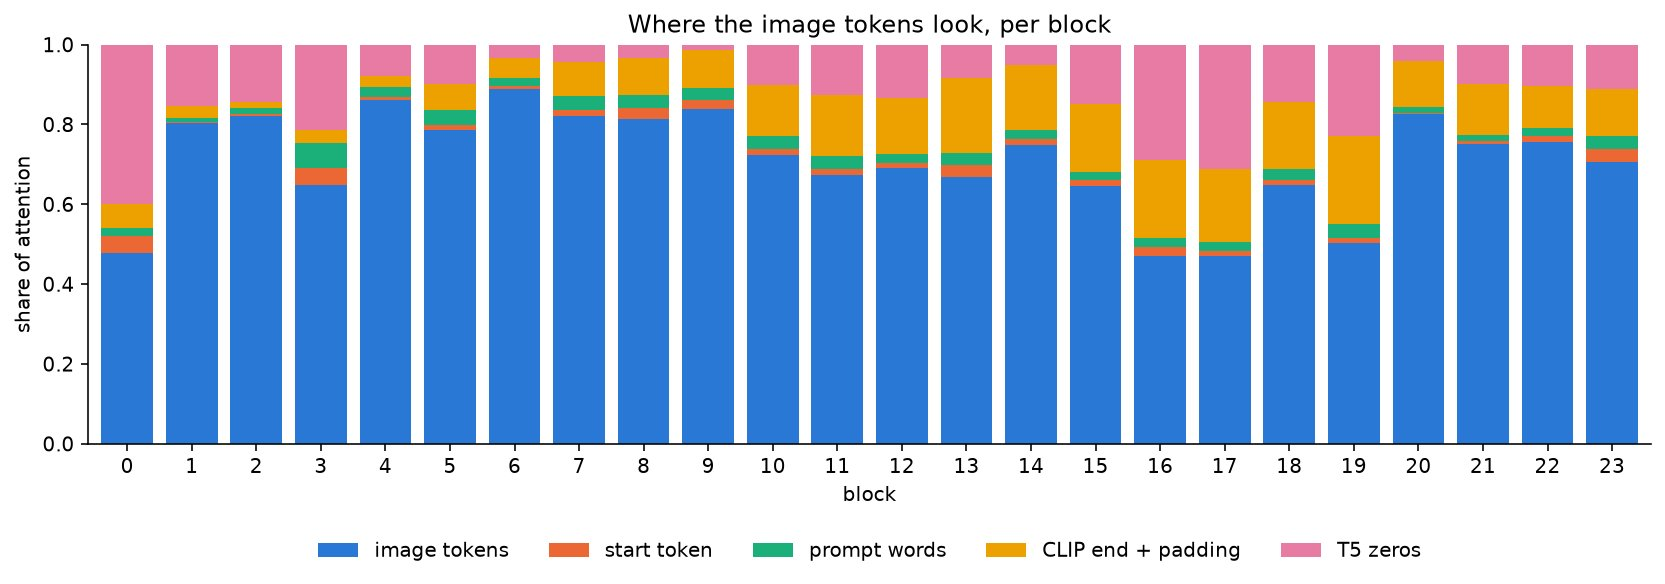

In [18]:
fig, ax = plt.subplots(figsize=(14, 3.6))
bottom = np.zeros(len(mass))
for color, column in zip(COLORS, mass.columns):
    ax.bar(mass.index, mass[column], bottom=bottom, color=color, label=column, width=0.8)
    bottom += mass[column].to_numpy()
ax.set(xlabel="block", ylabel="share of attention", xticks=range(24), xlim=(-0.6, 23.6), ylim=(0, 1),
       title="Where the image tokens look, per block")
ax.legend(loc="upper center", ncols=5, frameon=False, bbox_to_anchor=(0.5, -0.2))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

About 70% of the image tokens' attention stays among the image tokens: most of the work is arranging the image
itself. The prompt's **words** get only about 3%. More goes to the **end and padding tokens** of CLIP: CLIP's text
Transformer is causal, so every token after the last word has seen the whole prompt — they are summaries of it.
And a lot goes to the **256 zero tokens** that replace T5, especially in blocks 0, 16, 17 and 19, although they
carry no information about the prompt. Tokens with constant content are a convenient place to put attention that
has nowhere useful to go (an *attention sink*, also seen in language models); the 256 copies of the same vector
serve as one here.

Within the text part, the attention to each word is a map over the image. Averaged over all blocks:

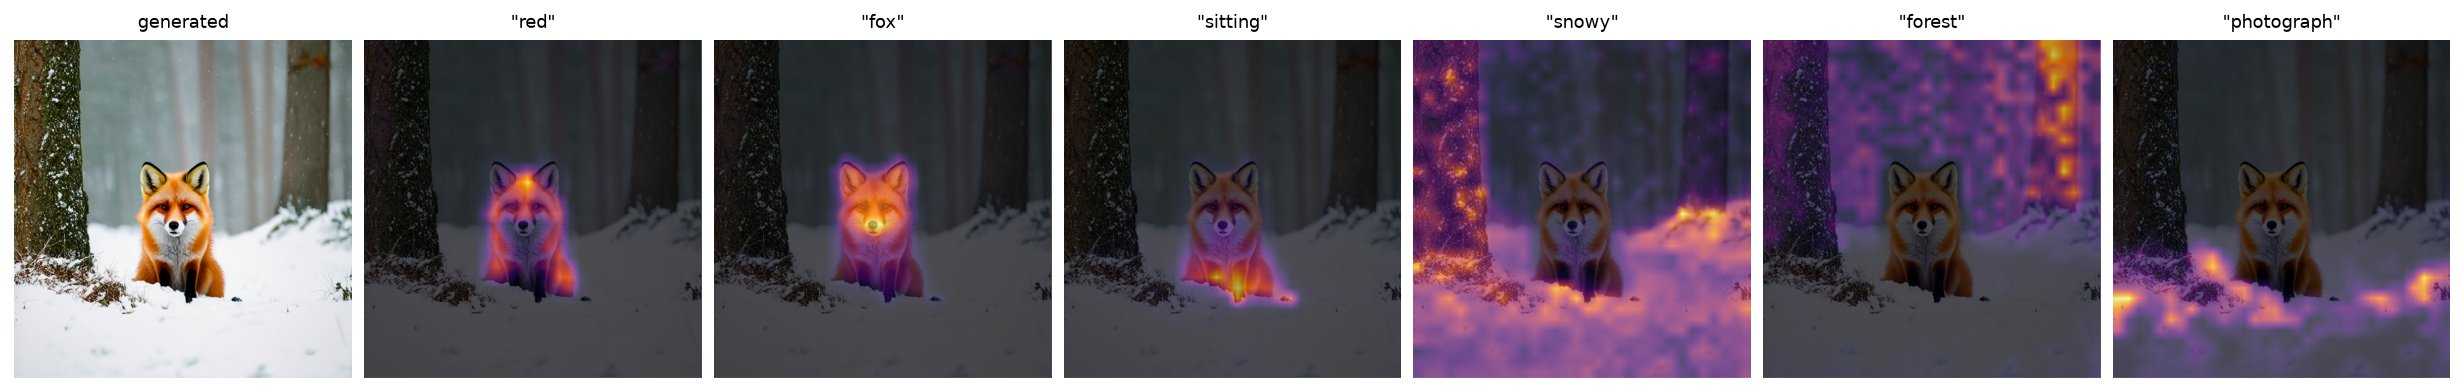

In [19]:
average = torch.stack(word_maps).mean(0)                               # (words, 32, 32)
shown = {w: m for w, m in zip(words[1:n_words - 1], average) if w.strip() in ["red", "fox", "sitting", "snowy",
                                                                                 "forest", "photograph"]}
fig, axes = plt.subplots(1, len(shown) + 1, figsize=(17, 2.9), layout="constrained")
axes[0].imshow(fox)
axes[0].set_title("generated", fontsize=9)
for ax, (word, attention) in zip(axes[1:], shown.items()):
    ax.imshow(fox)
    ax.imshow(attention / attention.max(), cmap="inferno", alpha=0.7, extent=(0, SIZE, SIZE, 0),
              interpolation="bilinear")
    ax.set_title(f'"{word.strip()}"', fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

Each word attends to its part of the image: "fox" and "red" to the fox, "sitting" to its legs and the ground,
"snowy" to the snow and the frost on the trunks, "forest" to the trees; "photograph", a word about style, is spread
over the whole image. Editing methods such as *prompt-to-prompt* work by manipulating maps like these.

**Dual attention.** Blocks 0–12 have a second attention, `attn2`, over the image tokens alone, and its output is
added after the joint one. This is the change from SD3 to SD3.5 Medium ("MMDiT-X"): extra image-only attention in
the early blocks, where the layout is decided, makes multi-resolution training more stable.

## 7. The noise level as a modulation (adaLN-Zero)

The MMDiT has to know how noisy its input is. The noise level $\sigma$ (times 1000, the *timestep*) is encoded with
sines and cosines and an MLP, the pooled text vector with another MLP, and the two are added into one vector
$c$ (1536). It doesn't enter as a token. Instead, it controls every `LayerNorm`, which has no scale and shift of its
own: for each block, `norm1.linear` computes from $c$ a **shift**, **scale** and **gate** for each branch:

$$h = x + g_\text{attn}(c) \odot \mathrm{Attn}\big(\mathrm{LN}(x) \odot (1 + s_\text{attn}(c)) + b_\text{attn}(c)\big)
\qquad y = h + g_\text{mlp}(c) \odot \mathrm{MLP}\big(\mathrm{LN}(h) \odot (1 + s_\text{mlp}(c)) + b_\text{mlp}(c)\big)$$

(*adaptive LayerNorm*; blocks 0–12 have a third set for `attn2`.) The gates were initialized to zero during training
("-Zero"), so every block started as the identity. The gates show how strongly each block's branches act at a given
noise level:

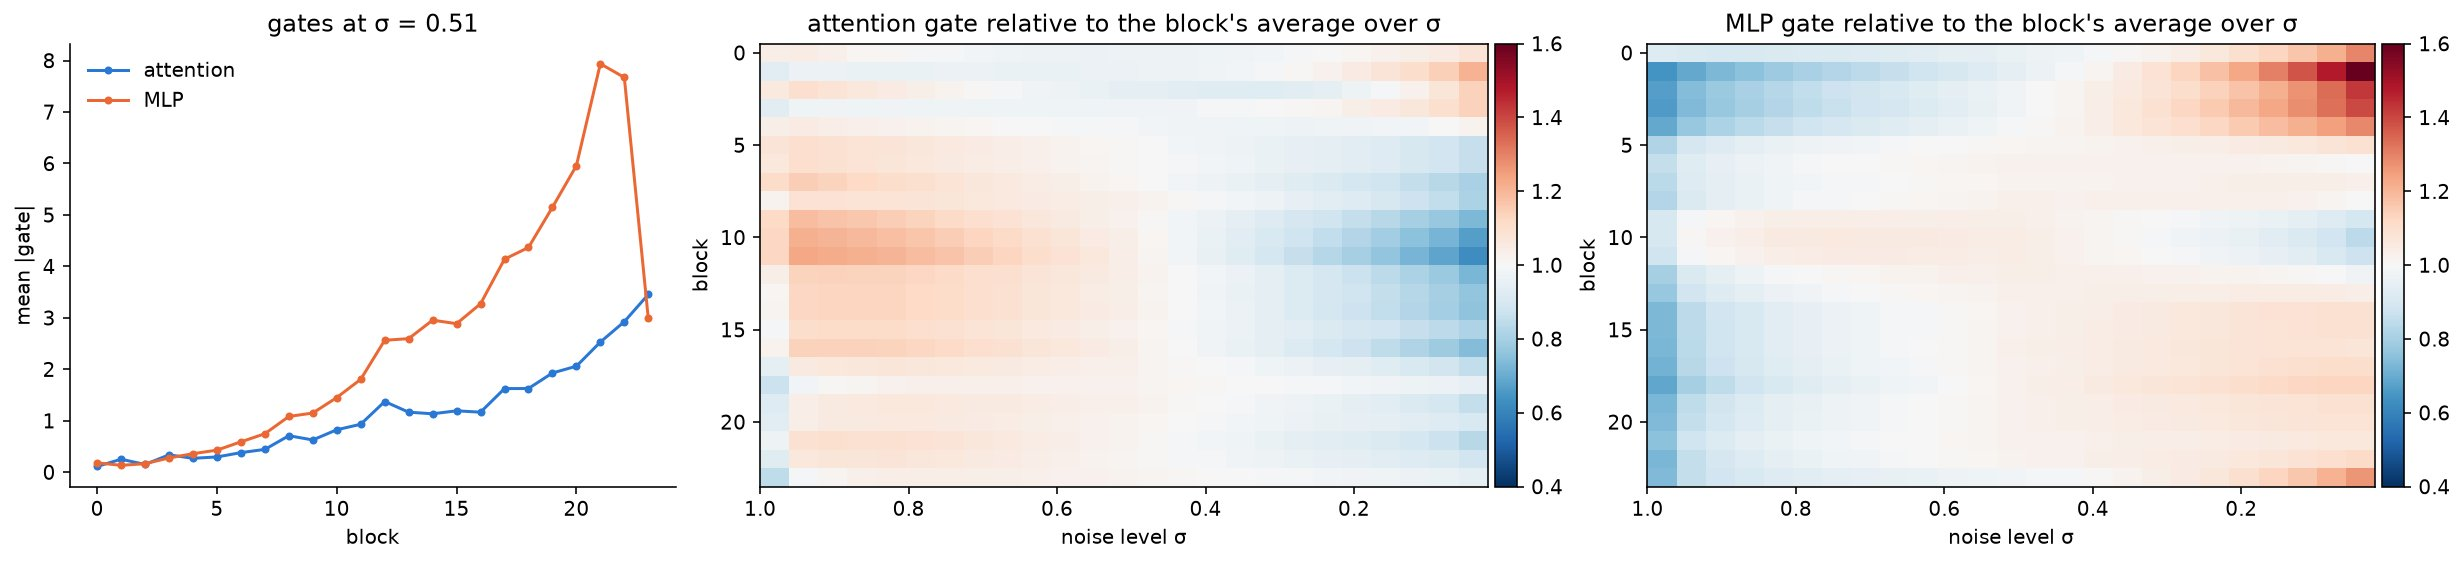

In [20]:
sigmas = torch.linspace(1, 0.02, 25)
gates = {"attention": [], "MLP": []}
with torch.no_grad():
    for s in sigmas:
        c = transformer.time_text_embed(torch.tensor([s * 1000], device=device), pooled)        # (1, 1536)
        attention, mlp = [], []
        for block in transformer.transformer_blocks:
            modulation = block.norm1.linear(block.norm1.silu(c)).chunk(9 if block.use_dual_attention else 6, dim=1)
            attention.append(modulation[2].abs().mean().item())                                # gate_msa
            mlp.append(modulation[5].abs().mean().item())                                      # gate_mlp
        gates["attention"].append(attention)
        gates["MLP"].append(mlp)

gates = {branch: np.array(values).T for branch, values in gates.items()}                    # (blocks, sigmas)
middle = int((sigmas - 0.5).abs().argmin())
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), layout="constrained", width_ratios=[1, 1.2, 1.2])
for color, (branch, values) in zip(COLORS, gates.items()):
    axes[0].plot(values[:, middle], "o-", ms=3, color=color, label=branch)
axes[0].set(xlabel="block", ylabel="mean |gate|", title=f"gates at σ = {sigmas[middle]:.2f}")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)
for ax, (branch, values) in zip(axes[1:], gates.items()):
    image = ax.imshow(values / values.mean(1, keepdims=True), aspect="auto", cmap="RdBu_r", vmin=0.4, vmax=1.6,
                      extent=(1, 0.02, 23.5, -0.5))
    ax.set(xlabel="noise level σ", ylabel="block", title=f"{branch} gate relative to the block's average over σ")
    fig.colorbar(image, ax=ax, pad=0.01)
plt.show()

Left: the gates grow with depth — the late blocks write more into the residual stream than the early ones. Middle and right: relative to each block's average, the gates depend on the noise level in a structured way.
The **attention** branches of the middle blocks are strongest at high noise, where the layout is decided and
tokens need to exchange information across the image; the **MLP** branches of the first blocks are strongest at low
noise, where only local detail is left to add. One network, steered by $c$, behaves differently at every step.

## 8. Sampling with rectified flow

**Training.** Take a training image's latent $x_0$ and Gaussian noise $\varepsilon$, choose a noise level
$\sigma \in [0, 1]$, and mix them on a straight line:

$$x_\sigma = (1 - \sigma)\, x_0 + \sigma\, \varepsilon$$

The MMDiT $v_\theta(x_\sigma, \sigma, \text{text})$ is trained to predict the direction of that line, the
**velocity** $v = \varepsilon - x_0$, with a squared error. (SD 1.x predicted the noise $\varepsilon$ along a curved
path instead.) From a velocity prediction, the clean latent can be estimated at any step:
$\hat x_0 = x_\sigma - \sigma\, v$.

**Sampling.** Start at pure noise ($\sigma = 1$) and move against the velocity in small Euler steps,
$x_{\sigma'} = x_\sigma + (\sigma' - \sigma)\, v_\theta(x_\sigma)$, down to $\sigma = 0$. The scheduler's 28 levels
are not evenly spaced: with `shift` $= 3$, $\sigma \mapsto 3\sigma / (1 + 2\sigma)$, more steps are spent at high noise,
where the layout of the image is decided.

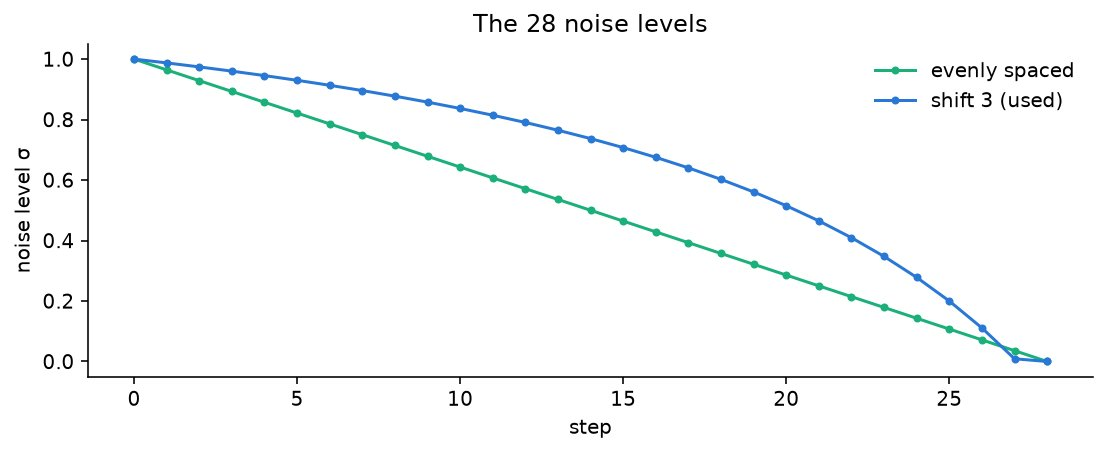

In [21]:
scheduler.set_timesteps(STEPS, device=device)
levels = scheduler.sigmas.cpu().numpy()                                 # 28 levels + the final 0
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.linspace(1, 0, STEPS + 1), "o-", ms=3, color=COLORS[2], label="evenly spaced")
ax.plot(levels, "o-", ms=3, color=COLORS[0], label=f"shift {scheduler.config.shift:g} (used)")
ax.set(xlabel="step", ylabel="noise level σ", title="The 28 noise levels")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Classifier-free guidance.** Each step runs the MMDiT twice, with the prompt and with the empty prompt (as a batch of
two), and extrapolates away from the unconditional prediction:

$$v = v_\text{empty} + w\,(v_\text{prompt} - v_\text{empty}), \qquad w = 5$$

The whole sampling loop, written out — it reproduces the pipeline's result from the start of section 2:

In [22]:
embeddings, pooled_both = torch.cat([negative_embeds, prompt_embeds]), torch.cat([negative_pooled, pooled])
x = randn_tensor((1, 16, SIZE // 8, SIZE // 8), generator=torch.Generator(device).manual_seed(SEED),
                 device=torch.device(device), dtype=dtype)
scheduler.set_timesteps(STEPS, device=device)
states, estimates = [], []
with torch.no_grad():
    for i, t in enumerate(scheduler.timesteps):
        v_empty, v_prompt = transformer(hidden_states=torch.cat([x, x]), timestep=t.expand(2),
                                        encoder_hidden_states=embeddings, pooled_projections=pooled_both,
                                        return_dict=False)[0].chunk(2)
        v = v_empty + GUIDANCE * (v_prompt - v_empty)
        sigma, sigma_next = scheduler.sigmas[i], scheduler.sigmas[i + 1]
        states.append(x)
        estimates.append(x - sigma * v)                                   # the clean latent, as seen from this step
        x = x + (sigma_next - sigma) * v                                  # Euler step
print("largest difference to the pipeline's latent:", (x - fox_latents).abs().max().item())

largest difference to the pipeline's latent: 0.0


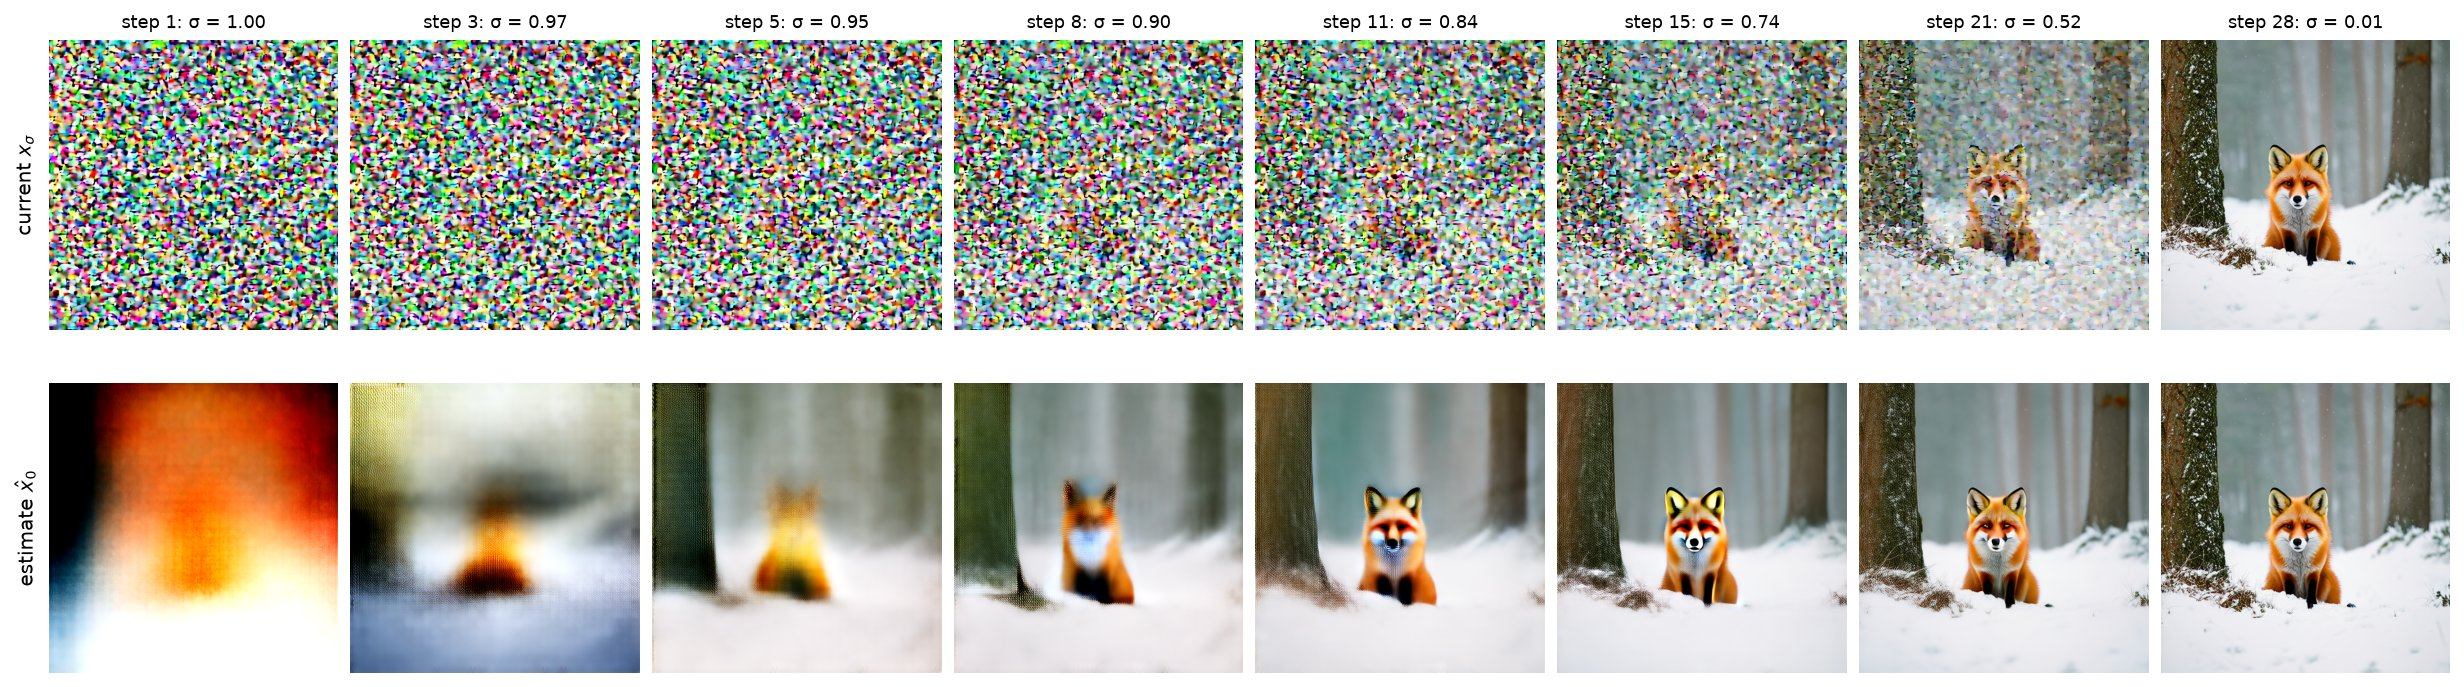

In [23]:
shown = [0, 2, 4, 7, 10, 14, 20, 27]
fig, axes = plt.subplots(2, len(shown), figsize=(17, 4.8), layout="constrained")
for column, i in enumerate(shown):
    axes[0, column].imshow(to_image(states[i]))
    axes[0, column].set_title(f"step {i + 1}: σ = {scheduler.sigmas[i]:.2f}", fontsize=9)
    axes[1, column].imshow(to_image(estimates[i]))
axes[0, 0].text(-40, SIZE / 2, "current $x_σ$", rotation=90, ha="center", va="center", fontsize=10)
axes[1, 0].text(-40, SIZE / 2, r"estimate $\hat x_0$", rotation=90, ha="center", va="center", fontsize=10)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
plt.show()

Top: the latent being denoised (decoded as it is, noise included). Bottom: the estimate $\hat x_0$ from each step.
The composition — a fox in front of trees, snow on the ground — is fixed after the first 3–5 steps, at
$\sigma > 0.9$ when the top row is still pure noise to the eye; the remaining steps sharpen and add detail. This is why
the shifted schedule puts its steps at high noise, and why distilled models (SD3.5 Large Turbo, SD-Turbo) can make an
image in 1–4 steps.

**The guidance scale** $w$: one prompt, the same noise, four values. $w = 1$ is plain conditional sampling (no
extrapolation).

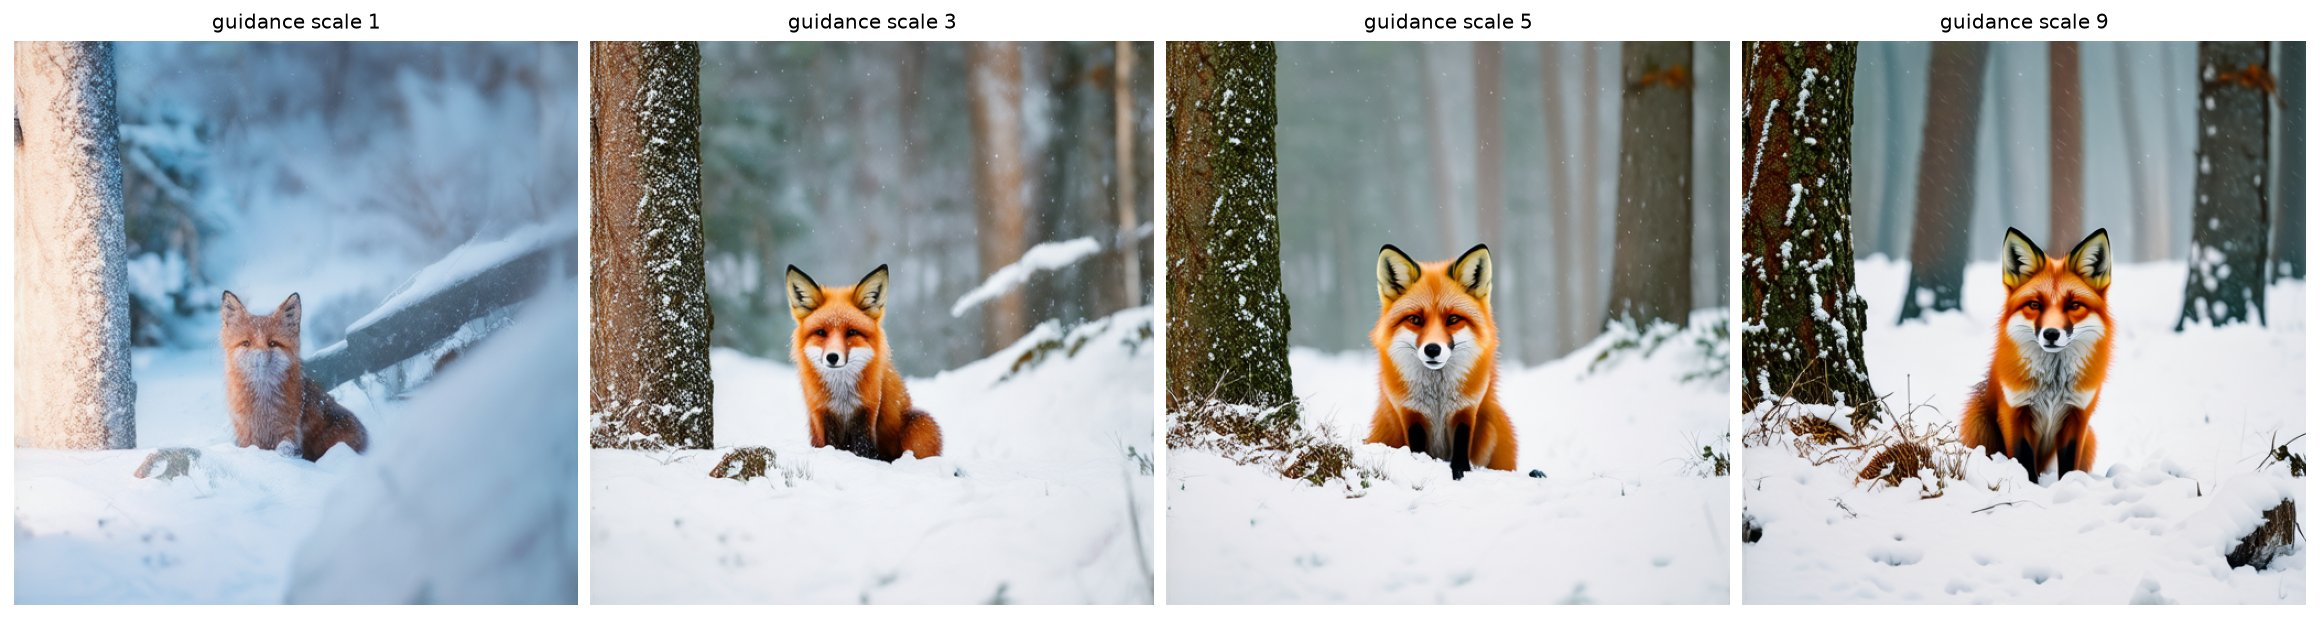

In [24]:
scales = [1.0, 3.0, 5.0, 9.0]
images = [pipe(PROMPT, height=SIZE, width=SIZE, num_inference_steps=STEPS, guidance_scale=w,
               generator=torch.Generator(device).manual_seed(SEED)).images[0] for w in scales]
fig, axes = plt.subplots(1, len(scales), figsize=(16, 4.3), layout="constrained")
for ax, w, image in zip(axes, scales, images):
    ax.imshow(image)
    ax.set_title(f"guidance scale {w:g}", fontsize=10)
    ax.axis("off")
plt.show()

Without guidance ($w = 1$) the image is a plausible but less typical answer to the prompt: dull colors, a small fox.
Larger $w$ gives more saturated, higher-contrast images with the fox as the centered subject; too large values
over-saturate. The price: two MMDiT passes per step instead of one.

## Summary

- **VAE**: 512 × 512 × 3 image ↔ 16 × 64 × 64 latent (12 × smaller), normalized to mean ≈ 0, std ≈ 1; generation
  happens entirely in the latent space;
- **Text**: CLIP-L and CLIP-G → 77 per-token vectors (2048, zero-padded to 4096) + a pooled vector (2048); the
  256 T5-XXL tokens are zeros here;
- **MMDiT** (2.2 B parameters): 2 × 2 patches → 1024 image tokens with fixed 2D sine positions; 24 blocks in which image
  and text tokens have separate weights but one **joint attention** (with RMS-normalized queries and keys), plus an
  image-only attention in blocks 0–12; the noise level and pooled text modulate every LayerNorm (**adaLN-Zero**);
  output: a velocity per latent position;
- **Sampling**: rectified flow — straight lines between data and noise, 28 Euler steps against the predicted
  velocity, with a shifted schedule and classifier-free guidance (two passes per step).